In [1]:
import sys
from pathlib import Path
import pandas as pd
import plotly.express as px

# Add project root to sys.path
project_root = str(Path.cwd().parent)
if project_root not in sys.path:
    sys.path.append(project_root)

from src.storage import fetch_table

# Fetch the full table from MySQL
df = fetch_table("SELECT * FROM product_listings;")
print(f"Loaded {len(df)} rows and {df.shape[1]} columns from MySQL.")
display(df.head())


Loaded 2021 rows and 15 columns from MySQL.


,title,rating,platform,position,price,review,Product,Brand,delivery_category,is_free_delivery,rank_visibility_score,price_range,price_vs_category_avg,title_discount_pct,category_discount_pct
0,Ninja 4-in-1 Air Fryer Pro,4.7,best buy,1.0,89.99,1300,air_fryer,Ninja,Free Delivery,1,100.0,Budget,0.00,0.0,99.69
1,DeWalt Small Angle Grinder DWE4011,4.4,home depot,1.0,59.00,749,grinder,Dewalt,Free Delivery,1,100.0,Mid-Range,0.40,0.0,64.46
2,Kerdom Ergonomic Office Chair,4.5,best buy,1.0,89.99,24,office_chair,Kerdom,Not Specified,0,100.0,Budget,0.00,0.0,99.74
3,Apple EarPods with Lightning Connector,4.6,apple,1.0,19.00,52000,head_phones,Apple,Free Delivery,1,100.0,Budget,0.06,0.0,91.42
4,Mainstays 3-in-1 Air Fry Convection Microwave ...,4.4,walmart,1.0,104.00,52,microwave_oven,Mainstays,Free Delivery,1,100.0,Budget,0.00,0.0,99.65


In [3]:
brand_stats = (
    df.groupby("Brand", as_index=False)
    .agg(
        total_listings=("title", "count"),
        avg_visibility=("rank_visibility_score", "mean"),
        avg_rating=("rating", "mean"),
        avg_price=("price", "mean"),
        total_reviews=("review", "sum")
    )
    .sort_values(by="total_listings", ascending=False)
    .head(15)
)

fig1 = px.bar(
    brand_stats,
    x="Brand",
    y="total_listings",
    color="avg_visibility",
    title="Top 15 Brands by Listing Count (Share of Shelf) & Avg Visibility",
    labels={"total_listings": "Number of Listings", "avg_visibility": "Avg Visibility Score"},
    color_continuous_scale="Viridis"
)
fig1.show()


In [4]:
platform_stats = (
    df.groupby("platform", as_index=False)
    .agg(
        listings=("title", "count"),
        avg_price=("price", "mean"),
        avg_visibility=("rank_visibility_score", "mean")
    )
    .sort_values(by="listings", ascending=False)
    .head(12)
)

fig2 = px.bar(
    platform_stats,
    x="listings",
    y="platform",
    orientation="h",
    color="avg_price",
    title="Top Platforms by Product Count & Average Price",
    labels={"listings": "Total Listings", "platform": "Retail Platform"}
)
fig2.update_layout(yaxis={"categoryorder": "total ascending"})
fig2.show()


In [5]:
fig3 = px.box(
    df,
    x="price_range",
    y="rank_visibility_score",
    color="price_range",
    title="Visibility Score Distribution Across Price Tiers",
    category_orders={"price_range": ["Budget", "Mid-Range", "Premium"]}
)
fig3.show()


In [6]:
product_stats = (
    df.groupby("Product", as_index=False)
    .agg(
        listings=("title", "count"),
        unique_brands=("Brand", "nunique"),
        avg_price=("price", "mean"),
        avg_visibility=("rank_visibility_score", "mean")
    )
    .sort_values(by="listings", ascending=False)
)

display(product_stats)

fig4 = px.scatter(
    product_stats,
    x="avg_price",
    y="avg_visibility",
    size="listings",
    color="Product",
    hover_name="Product",
    title="Product Categories: Avg Price vs. Visibility (Bubble Size = Listings)"
)
fig4.show()


,Product,listings,unique_brands,avg_price,avg_visibility
9,power_bank,333,53,20706.617477,8.138408
6,men_running_shoes,331,28,21538.176767,7.696375
7,microwave_oven,330,42,24906.615848,6.003242
0,air_fryer,326,46,21706.547546,6.987638
8,office_chair,282,40,28323.101702,4.728865
5,head_phones,91,35,329.967582,26.720659
10,smart_phone,80,18,493.563625,28.764000
11,washing_machine,74,23,693.894459,27.328378
4,grinder,65,34,148.296923,28.388462
3,chopper,55,34,135.277636,27.383818


Trends Across Brands, Platforms, and Pricing

In [9]:
#Brand Dominance & Share of Shelf

brand_trends = (
    df.groupby("Brand", as_index=False)
    .agg(
        listings=("title", "count"),
        share_of_shelf_pct=("title", lambda x: round(len(x) / len(df) * 100, 2)),
        categories_covered=("Product", "nunique"),
        avg_price=("price", "mean"),
        avg_rating=("rating", "mean"),
        avg_position=("position", "mean"),
        avg_visibility=("rank_visibility_score", "mean")
    )
    .sort_values(by="listings", ascending=False)
)

display(brand_trends.head(15))

fig_brand = px.scatter(
    brand_trends.head(25),
    x="listings",
    y="avg_visibility",
    size="share_of_shelf_pct",
    color="avg_price",
    hover_name="Brand",
    title="Top 25 Brands: Listing Volume vs. Average Visibility Score",
    labels={"listings": "Total Listings", "avg_visibility": "Avg Visibility Score"}
)
fig_brand.show()


,Brand,listings,share_of_shelf_pct,categories_covered,avg_price,avg_rating,avg_position,avg_visibility
159,Lg,168,8.31,7,24715.691310,3.817560,22.466667,2.172083
240,Samsung,165,8.16,7,18868.861212,3.852121,19.805556,6.119273
133,Hp,156,7.72,5,31322.128205,3.888782,NaN,0.000000
191,Nike,155,7.67,5,28363.993548,3.891613,20.105263,4.051097
230,Puma,138,6.83,5,34342.456304,3.868116,13.333333,0.793406
220,Philips,138,6.83,5,24576.452101,3.825725,25.250000,0.625942
48,Boat,134,6.63,5,38054.451493,3.853358,NaN,0.000000
255,Sony,126,6.23,7,27249.570873,3.936111,26.222222,1.705159
75,Dell,120,5.94,5,33530.533333,3.815000,NaN,0.000000
21,Apple,20,0.99,2,607.817500,4.540000,18.600000,35.533500


In [11]:
#B. Platform Strategy & Pricing Positioning
platform_trends = (
    df.groupby("platform", as_index=False)
    .agg(
        listings=("title", "count"),
        unique_brands=("Brand", "nunique"),
        median_price=("price", "median"),
        avg_price=("price", "mean"),
        avg_rating=("rating", "mean"),
        free_delivery_pct=("is_free_delivery", lambda x: round(x.mean() * 100, 1)),
        avg_visibility=("rank_visibility_score", "mean")
    )
    .sort_values(by="listings", ascending=False)
)

display(platform_trends.head(15))

# Stacked bar: Price Range breakdown across top 10 platforms
top_10_platforms = platform_trends.head(10)["platform"].tolist()
plat_price_mix = (
    df[df["platform"].isin(top_10_platforms)]
    .groupby(["platform", "price_range"], as_index=False)
    .size()
)

fig_plat = px.bar(
    plat_price_mix,
    x="platform",
    y="size",
    color="price_range",
    title="Price Tier Mix Across Top 10 Retail Platforms",
    labels={"size": "Product Count", "platform": "Platform"},
    category_orders={"price_range": ["Budget", "Mid-Range", "Premium"]}
)
fig_plat.show()


,platform,listings,unique_brands,median_price,avg_price,avg_rating,free_delivery_pct,avg_visibility
207,reliance digital,323,9,22209.000,34211.860681,3.774613,36.8,0.000000
13,amazon,313,9,18469.000,32232.650160,3.835623,34.8,0.000000
59,croma,296,9,17190.500,27219.707770,3.840203,29.4,0.000000
97,flipkart,282,9,21112.500,28384.388298,3.831560,40.4,0.000000
31,best buy,100,49,82.490,251.234400,4.429000,40.0,33.584700
119,home depot,64,36,174.000,361.849531,4.265625,62.5,29.261094
244,target,51,30,59.990,79.537059,4.131373,64.7,29.923725
267,walmart,38,28,47.455,119.671053,4.068421,52.6,29.152105
142,lowe's,20,17,204.000,373.107000,4.205000,50.0,25.246000
137,kohl's,15,9,59.990,67.768667,4.520000,73.3,33.208667


In [12]:
#Patterns in Search Ranking vs. Price & Rating

ranked_df = df[df["position"].notna()].copy()

# 1. Correlation matrix between Search Position, Price, Rating, Reviews, and Free Delivery
corr_cols = ["position", "price", "price_vs_category_avg", "rating", "review", "is_free_delivery", "rank_visibility_score"]
corr_matrix = ranked_df[corr_cols].corr().round(3)

fig_corr = px.imshow(
    corr_matrix,
    text_auto=True,
    color_continuous_scale="RdBu_r",
    title="Correlation Matrix: Search Position vs. Price, Rating & Reviews"
)
fig_corr.show()

# 2. Group search positions into Rank Buckets (Top 5, Top 6-15, Top 16-30, 31+)
ranked_df["rank_bucket"] = pd.cut(
    ranked_df["position"],
    bins=[0, 5, 15, 30, 100],
    labels=["Top 5 (Page Top)", "6–15 (Upper Fold)", "16–30 (Mid Page)", "31+ (Lower Page)"]
)

rank_patterns = (
    ranked_df.groupby("rank_bucket", observed=False, as_index=False)
    .agg(
        count=("title", "count"),
        median_price=("price", "median"),
        avg_relative_price=("price_vs_category_avg", "mean"),
        avg_rating=("rating", "mean"),
        median_reviews=("review", "median"),
        free_delivery_pct=("is_free_delivery", lambda x: round(x.mean() * 100, 1))
    )
)

display(rank_patterns)


,rank_bucket,count,median_price,avg_relative_price,avg_rating,median_reviews,free_delivery_pct
0,Top 5 (Page Top),98,62.380,0.279592,4.413265,871.0,45.9
1,6–15 (Upper Fold),213,99.990,0.605728,4.368545,276.0,59.6
2,16–30 (Mid Page),302,99.990,0.516391,4.332450,249.0,57.6
3,31+ (Lower Page),194,129.955,0.570412,4.367526,285.5,58.2


🟦 General Market Analysis
How many total products are available per keyword?
What is the overall average price of products?
What is the distribution of price across all products?
What is the average rating across all products?
How are reviews distributed (low vs high engagement products)?


In [14]:
df['price'] = pd.to_numeric(df['price'], errors='coerce')
df['rating'] = pd.to_numeric(df['rating'], errors='coerce')
df['review'] = pd.to_numeric(df['review'], errors='coerce')

In [15]:
avg_price = df['price'].mean()
median_price = df['price'].median()

print(f"Mean Price: {avg_price:.2f}")
print(f"Median Price: {median_price:.2f}")


Mean Price: 18529.35
Median Price: 8744.00


In [16]:
# 1. Statistical distribution (min, 25%, 50%, 75%, max)
print(df['price'].describe())

# 2. Custom price buckets (adjust bins to fit your currency/market)
price_bins = [0, 500, 1500, 5000, float('inf')]
price_labels = ['Budget (<500)', 'Mid-Range (500-1.5k)', 'Premium (1.5k-5k)', 'Luxury (5k+)']

df['price_tier'] = pd.cut(df['price'], bins=price_bins, labels=price_labels)
print(df['price_tier'].value_counts(normalize=True) * 100)  # Percentage share


count      2021.000000
mean      18529.352459
std       43638.733375
min           3.110000
25%         169.000000
50%        8744.000000
75%       24681.000000
max      498050.000000
Name: price, dtype: float64
price_tier
Luxury (5k+)            53.884216
Budget (<500)           32.409698
Mid-Range (500-1.5k)     8.708560
Premium (1.5k-5k)        4.997526
Name: proportion, dtype: float64


In [ ]:

overall_rating = df['rating'].mean()

rated_only_avg = df.loc[df['rating'] > 0, 'rating'].mean()

print(f"Overall Avg Rating: {overall_rating:.2f}")
print(f"Rated Products Avg: {rated_only_avg:.2f}")


Overall Avg Rating: 4.04
Rated Products Avg: 4.04


In [19]:

print(df['review'].describe())

# Segment into engagement tiers
review_bins = [-1, 0, 50, 500, float('inf')]
review_labels = ['No Reviews (0)', 'Low Engagement (1-50)', 'Moderate (51-500)', 'High Engagement (500+)']

df['engagement_tier'] = pd.cut(df['review'], bins=review_bins, labels=review_labels)
print(df['engagement_tier'].value_counts())


count      2021.000000
mean       2662.147452
std        7509.463568
min           0.000000
25%         355.000000
50%        1593.000000
75%        3377.000000
max      207000.000000
Name: review, dtype: float64
engagement_tier
High Engagement (500+)    1436
Moderate (51-500)          343
Low Engagement (1-50)      163
No Reviews (0)              79
Name: count, dtype: int64


In [23]:
market_summary = df.groupby('Product').agg(
    total_products=('price', 'count'),
    avg_price=('price', 'mean'),
    median_price=('price', 'median'),
    avg_rating=('rating', 'mean'),
    total_reviews=('review', 'sum')
).round(2)

print(market_summary)


                   total_products  avg_price  median_price  avg_rating  \
Product                                                                  
air_fryer                     326   21706.55      15144.00        3.97   
bluetooth                      38      23.95         18.43        4.36   
bluetooth_speaker              16     118.66         69.95        4.73   
chopper                        55     135.28         24.95        4.16   
grinder                        65     148.30         74.99        4.39   
head_phones                    91     329.97         99.99        4.52   
men_running_shoes             331   21538.18      10750.00        3.98   
microwave_oven                330   24906.62      13302.00        3.83   
office_chair                  282   28323.10      18208.50        3.89   
power_bank                    333   20706.62      13789.50        4.07   
smart_phone                    80     493.56        329.99        4.35   
washing_machine                74     

In [24]:
for col in ['visibility_score', 'rating', 'position', 'price', 'reviews']:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')



In [26]:

# 1. Which brand appears most frequently?
brand_counts = df['Brand'].value_counts()
most_frequent_brand = brand_counts.idxmax()
print(f"Most Frequent Brand: {most_frequent_brand} ({brand_counts.max()} listings)\n")
print("Top 10 Brands by Frequency:\n", brand_counts.head(10), "\n")

Most Frequent Brand: Lg (168 listings)

Top 10 Brands by Frequency:
 Brand
Lg         168
Samsung    165
Hp         156
Nike       155
Puma       138
Philips    138
Boat       134
Sony       126
Dell       120
Apple       20
Name: count, dtype: int64 



In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

Matplotlib is building the font cache; this may take a moment.


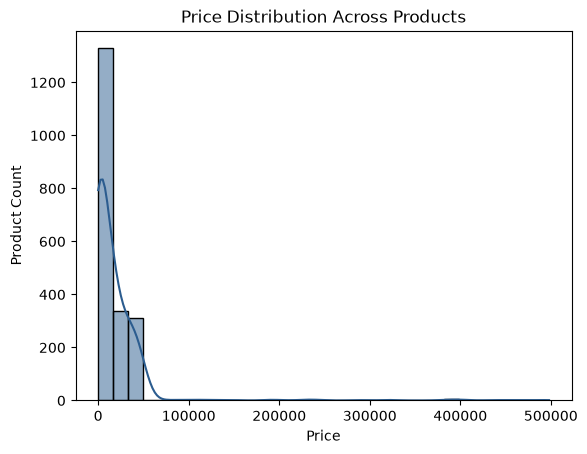

In [38]:
sns.histplot(df['price'].dropna(), bins=30, kde=True, color="#2b5c8f")
plt.title("Price Distribution Across Products")
plt.xlabel("Price")
plt.ylabel("Product Count")
plt.show()

In [28]:
# 2. Which brand has the highest average visibility_score?
avg_visibility = df.groupby('Brand')['rank_visibility_score'].mean().sort_values(ascending=False)
print("Top 10 Brands by Avg Visibility Score:\n", avg_visibility.head(10).round(2), "\n")

Top 10 Brands by Avg Visibility Score:
 Brand
Power        100.00
Mini          63.09
Casabay       63.09
Insignia      56.23
Kitchen       50.64
Kerdom        50.40
Monster       49.23
Bluetooth     47.06
Mainstays     46.52
Groove        43.07
Name: rank_visibility_score, dtype: float64 



C:\Users\ADMIN\AppData\Local\Temp\ipykernel_19232\3552526414.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Product', y='price', palette="Blues")


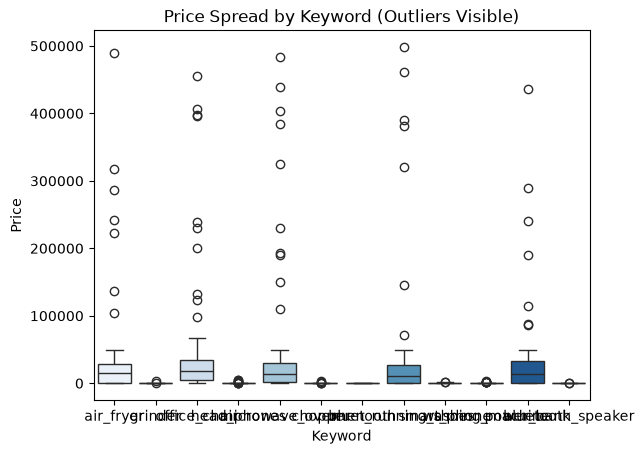

In [42]:
sns.boxplot(data=df, x='Product', y='price', palette="Blues")
plt.title("Price Spread by Keyword (Outliers Visible)")
plt.xlabel("Keyword")
plt.ylabel("Price")
plt.show()

In [29]:
# 3. What is the average rating per brand? (All brands)
avg_rating_all = df.groupby('Brand')['rating'].mean().sort_values(ascending=False)
print("Average Rating per Brand:\n", avg_rating_all.round(2), "\n")


Average Rating per Brand:
 Brand
Toshiba        5.00
Thor           5.00
Smartcharge    5.00
45Qt           5.00
Asko           5.00
               ... 
Koolmore       2.93
Farberware     2.80
Mototec        2.35
Figmint        2.00
Impecca        1.00
Name: rating, Length: 298, dtype: float64 



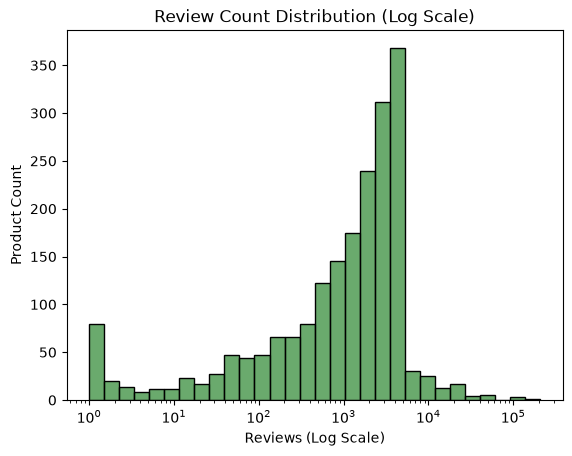

In [44]:
sns.histplot(df['review'].dropna() + 1, bins=30, log_scale=True, color="#388e3c")
plt.title("Review Count Distribution (Log Scale)")
plt.xlabel("Reviews (Log Scale)")
plt.ylabel("Product Count")
plt.show()


In [30]:
# 4. Which brands appear most in top 10 positions (position <= 10)?
top_10_positions = df.loc[df['position'] <= 10, 'Brand'].value_counts()
print("Brands Appearing Most in Top 10 Positions (position <= 10):\n", top_10_positions.head(10), "\n")

Brands Appearing Most in Top 10 Positions (position <= 10):
 Brand
Samsung    9
Apple      8
Anker      6
Adidas     6
Ninja      5
Nike       5
Ge         5
Ugreen     5
Jbl        5
Google     4
Name: count, dtype: int64 



C:\Users\ADMIN\AppData\Local\Temp\ipykernel_19232\3497438317.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_freq.values, y=top_freq.index, palette="viridis")


Text(0, 0.5, 'Brand')

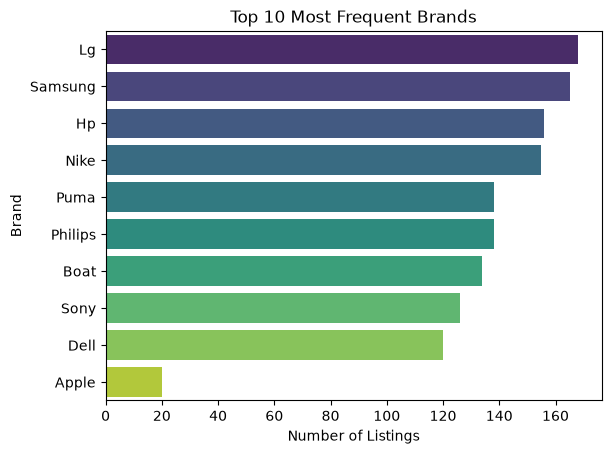

In [45]:
top_freq = df['Brand'].value_counts().head(10)
sns.barplot(x=top_freq.values, y=top_freq.index, palette="viridis")
plt.title("Top 10 Most Frequent Brands")
plt.xlabel("Number of Listings")
plt.ylabel("Brand")

In [31]:
brand_stats = df.groupby('Brand').agg(
    product_count=('rating', 'count'),
    avg_rating=('rating', 'mean'),
    avg_visibility=('rank_visibility_score', 'mean')
)

reliable_top_rated = (
    brand_stats.loc[brand_stats['product_count'] >= 3]
    .sort_values(by='avg_rating', ascending=False)
)
print("Highest Rated Brands (Min. 3 Products):\n", reliable_top_rated.head(10).round(2))

Highest Rated Brands (Min. 3 Products):
               product_count  avg_rating  avg_visibility
Brand                                                  
Baseus                    6        4.80           23.35
Beyerdynamic              4        4.80           25.21
Tp-Link                   5        4.76           24.87
Audio                     4        4.75           21.48
Vevor                     3        4.73           20.41
Iniu                      7        4.70           36.34
Hercules                  3        4.70           30.38
Ridge                     3        4.70           31.67
Sennheiser                5        4.70           21.89
Ugreen                    7        4.69           38.80


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_19232\754712959.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_vis.values, y=top_vis.index, palette="magma")


Text(0, 0.5, '')

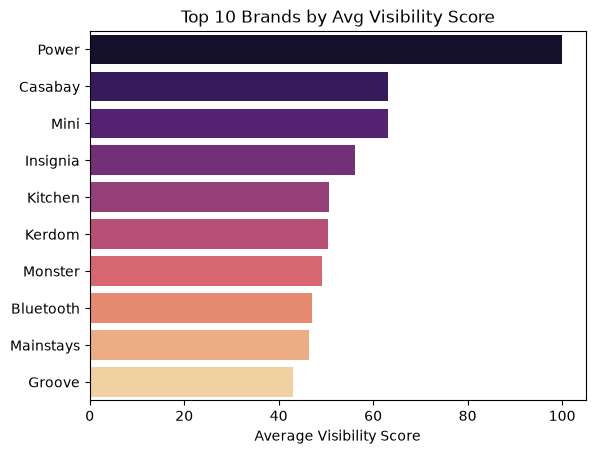

In [46]:
top_vis = df.groupby('Brand')['rank_visibility_score'].mean().nlargest(10)
sns.barplot(x=top_vis.values, y=top_vis.index, palette="magma")
plt.title("Top 10 Brands by Avg Visibility Score")
plt.xlabel("Average Visibility Score")
plt.ylabel("")

🟨 Pricing Analysis
What is the price distribution across different brands?
How are products distributed across price_range categories?
Do higher-priced products have better rankings (rating)?
What is the average price per platform?


In [48]:
top_brands = df["Brand"].value_counts().head(10).index
q1_df = (
    df[df["Brand"].isin(top_brands)]
    .groupby("Brand", as_index=False)["price"]
    .median()
    .sort_values(by="price", ascending=False)
    .round(2)
)

print(f"Answer Q1: Highest median price among top brands is {q1_df.iloc[0]['Brand']} (${q1_df.iloc[0]['price']}), lowest is {q1_df.iloc[-1]['Brand']} (${q1_df.iloc[-1]['price']}).")

fig1 = px.bar(q1_df, x="Brand", y="price", text="Brand", title="Median Price by Top 10 Brands ($)")
fig1.update_traces(texttemplate="%{x}<br>$%{y:.0f}", textposition="outside")
fig1.update_xaxes(visible=False)
fig1.update_yaxes(visible=False)
fig1.show()


Answer Q1: Highest median price among top brands is Dell ($23601.5), lowest is Apple ($589.5).


In [49]:
q2_df = df["price_range"].value_counts().reset_index().rename(columns={"count": "products"})
q2_df["pct"] = (q2_df["products"] / len(df) * 100).round(1)

print("Answer Q2:", dict(zip(q2_df["price_range"], q2_df["products"])))

fig2 = px.pie(q2_df, names="price_range", values="products", hole=0.45, title="Product Distribution Across Price Tiers")
fig2.update_traces(textinfo="label+percent+value")
fig2.show()


Answer Q2: {'Budget': 678, 'Premium': 672, 'Mid-Range': 671}


In [50]:
ranked_df = df[df["position"].notna()]
corr_pos = ranked_df["price"].corr(ranked_df["position"]).round(3)
corr_rat = df["price"].corr(df["rating"]).round(3)

q3_df = (
    df.groupby("price_range", observed=False, as_index=False)
    .agg(avg_position=("position", "mean"), avg_rating=("rating", "mean"))
    .round(2)
)

print(f"Answer Q3: Correlation with Search Position = {corr_pos}, Correlation with Rating = {corr_rat}.")
display(q3_df)

fig3 = px.bar(
    q3_df,
    x="price_range",
    y="avg_position",
    text="avg_position",
    title="Avg Search Position by Price Tier (Lower = Better Rank)",
    category_orders={"price_range": ["Budget", "Mid-Range", "Premium"]}
)
fig3.update_traces(texttemplate="Rank #%{text}", textposition="outside")
fig3.update_xaxes(visible=False)
fig3.update_yaxes(visible=False)
fig3.show()


Answer Q3: Correlation with Search Position = 0.056, Correlation with Rating = -0.124.


,price_range,avg_position,avg_rating
0,Budget,19.80,4.24
1,Mid-Range,20.06,3.89
2,Premium,22.53,3.98


In [52]:
q4_df = (
    df.groupby("platform", as_index=False)
    .agg(listings=("price", "count"), avg_price=("price", "mean"))
    .sort_values(by="listings", ascending=False)
    .head(10)
    .sort_values(by="avg_price", ascending=False)
    .round(2)
)

print(f"Answer Q4: Highest avg price platform (top 10 volume) is {q4_df.iloc[0]['platform']} (${q4_df.iloc[0]['avg_price']}).")

fig4 = px.bar(q4_df, x="platform", y="avg_price", text="platform", title="Average Price Across Top 10 Platforms ($)")
fig4.update_traces(texttemplate="%{x}<br>$%{y:.0f}", textposition="outside")
fig4.update_xaxes(visible=False)
fig4.update_yaxes(visible=False)
fig4.show()


Answer Q4: Highest avg price platform (top 10 volume) is reliance digital ($34211.86).


In [53]:
# Find the row with the maximum price inside each Product (keyword) category
idx_max = df.groupby("Product")["price"].idxmax()
highest_per_kw = (
    df.loc[idx_max, ["Product", "Brand", "title", "price", "platform"]]
    .sort_values(by="price", ascending=False)
    .reset_index(drop=True)
)

# Shorten title slightly for clean chart labels
highest_per_kw["short_label"] = (
    highest_per_kw["Product"] + " (" + highest_per_kw["Brand"] + ")"
)

print("Highest-Priced Product per Keyword Category:")
display(highest_per_kw[["Product", "Brand", "title", "price", "platform"]])

# Single clean horizontal bar chart without axes
fig = px.bar(
    highest_per_kw,
    x="price",
    y="short_label",
    orientation="h",
    text="price",
    hover_data=["title", "platform"],
    title="Highest-Priced Product Within Each Keyword Category ($)"
)
fig.update_traces(
    texttemplate="%{y}: $%{x:,.0f}",
    textposition="outside"
)
fig.update_layout(yaxis={"categoryorder": "total ascending"})
fig.update_xaxes(visible=False)
fig.update_yaxes(visible=False)
fig.show()


Highest-Priced Product per Keyword Category:


,Product,Brand,title,price,platform
0,men_running_shoes,Hp,HP men running shoes Model 483 !!!,498050.00,amazon
1,air_fryer,Nike,Nike air fryer India Model 162 !!!,489880.00,flipkart
2,microwave_oven,Boat,Boat microwave oven convection Model 424,482890.00,amazon
3,office_chair,Boat,Boat office chair ergonomic Model 324,455330.00,amazon
4,power_bank,Nike,Nike power bank fast charging Model 406 !!!,436130.00,reliance digital
5,head_phones,Focal,Focal Utopia 2022 Open-Back Headphones,4999.00,audio46 headphone store
6,grinder,Dake,Dake BG-60V Benchtop Belt Grinder,3250.00,beaver industrial supply
7,chopper,Tracer,Tracer Beyond Pro Chopper Electric Bike,2599.99,tracer bikes
8,washing_machine,Asko,ASKO 5 Series 2.8 Cu. ft Steel Seal Front Load...,2599.00,snow bros. appliance
9,smart_phone,Samsung,Samsung Galaxy Z Fold7 512GB Unlocked Blue Shadow,2119.99,walmart


🟥 Discount & Offer Analysis
What percentage of products have a non-zero discount?
Do discounted products have better rankings (rating)?
Which brand offers the highest average discount?
Which platform provides the highest average discount?
Is there a relationship between discount and rating?


In [57]:
DISC_COL = ["category_discount_pct"]

In [58]:
df["has_discount"] = df[DISC_COL] > 0
q1_disc = (
    df["has_discount"]
    .map({True: "Discounted (> 0%)", False: "No Discount (0%)"})
    .value_counts()
    .reset_index()
    .rename(columns={"count": "products"})
)
pct_discounted = (df["has_discount"].mean() * 100).round(2)

print(f"Answer Q1: {pct_discounted}% of products ({df['has_discount'].sum()} out of {len(df)}) have a non-zero discount.")

fig_d1 = px.pie(
    q1_disc,
    names="has_discount",
    values="products",
    hole=0.45,
    title="Share of Products with Non-Zero Discount"
)
fig_d1.update_traces(textinfo="label+percent+value")
fig_d1.show()


Answer Q1: 74.72% of products (1510 out of 2021) have a non-zero discount.


In [59]:
q2_disc_rank = (
    df.groupby("has_discount", as_index=False)
    .agg(
        count=("title", "count"),
        avg_position=("position", "mean"),
        avg_rating=("rating", "mean")
    )
    .round(2)
)
q2_disc_rank["status"] = q2_disc_rank["has_discount"].map({True: "Discounted", False: "No Discount"})

print("Answer Q2: Comparison of Search Position (lower = better) and Rating:")
display(q2_disc_rank[["status", "count", "avg_position", "avg_rating"]])

fig_d2 = px.bar(
    q2_disc_rank,
    x="status",
    y="avg_position",
    text="avg_position",
    title="Avg Search Position: Discounted vs. Non-Discounted (Lower = Better Rank)"
)
fig_d2.update_traces(texttemplate="%{x}<br>Rank #%{y}", textposition="outside")
fig_d2.update_xaxes(visible=False)
fig_d2.update_yaxes(visible=False)
fig_d2.show()


Answer Q2: Comparison of Search Position (lower = better) and Rating:


,status,count,avg_position,avg_rating
0,No Discount,511,22.37,3.97
1,Discounted,1510,19.99,4.06


In [61]:
# Filter for brands with at least 3 listings to avoid single-product outliers
brand_counts = df["Brand"].value_counts()
valid_brands = brand_counts[brand_counts >= 3].index

q3_brand_disc = (
    df[df["Brand"].isin(valid_brands)]
    .groupby("Brand", as_index=False)[DISC_COL]
    .mean()
    .sort_values(by=DISC_COL, ascending=False)
    .head(10)
    .round(2)
)

print(f"Answer Q3: Highest avg discount brand (min 3 listings) is {q3_brand_disc.iloc[0]['Brand']} ({q3_brand_disc.iloc[0][DISC_COL]}%).")

fig_d3 = px.bar(
    q3_brand_disc,
    x="Brand",
    y=DISC_COL,
    text="Brand",
    title="Top 10 Brands by Average Discount (%)"
)
fig_d3.update_traces(texttemplate="%{x}<br>%{y:.1f}%", textposition="outside")
fig_d3.update_xaxes(visible=False)
fig_d3.update_yaxes(visible=False)
fig_d3.show()


Answer Q3: Highest avg discount brand (min 3 listings) is Magnetic (category_discount_pct    99.93
Name: 52, dtype: object%).


In [62]:
# Filter for platforms with at least 5 listings for reliable averages
plat_counts = df["platform"].value_counts()
valid_plats = plat_counts[plat_counts >= 5].index

q4_plat_disc = (
    df[df["platform"].isin(valid_plats)]
    .groupby("platform", as_index=False)[DISC_COL]
    .mean()
    .sort_values(by=DISC_COL, ascending=False)
    .head(10)
    .round(2)
)

print(f"Answer Q4: Highest avg discount platform (min 5 listings) is {q4_plat_disc.iloc[0]['platform']} ({q4_plat_disc.iloc[0][DISC_COL]}%).")

fig_d4 = px.bar(
    q4_plat_disc,
    x="platform",
    y=DISC_COL,
    text="platform",
    title="Top 10 Platforms by Average Discount (%)"
)
fig_d4.update_traces(texttemplate="%{x}<br>%{y:.1f}%", textposition="outside")
fig_d4.update_xaxes(visible=False)
fig_d4.update_yaxes(visible=False)
fig_d4.show()


Answer Q4: Highest avg discount platform (min 5 listings) is anker us (category_discount_pct    99.71
Name: 2, dtype: object%).


In [65]:
DISC_COL = "category_discount_pct"  # Ensure this matches your exact discount column in df

corr_disc_rat = round(df[DISC_COL].corr(df["rating"]), 3)

df["discount_tier"] = pd.cut(
    df[DISC_COL],
    bins=[-1, 0, 15, 30, 100],
    labels=["0% (None)", "1-15% (Low)", "16-30% (Medium)", "30%+ (High)"]
)

q5_disc_rat = (
    df.groupby("discount_tier", observed=False, as_index=False)
    .agg(products=("rating", "count"), avg_rating=("rating", "mean"))
    .round(2)
)

print(f"Answer Q5: Correlation between Discount % and Rating = {corr_disc_rat}")
display(q5_disc_rat)

fig_d5 = px.bar(
    q5_disc_rat,
    x="discount_tier",
    y="avg_rating",
    text="avg_rating",
    title="Average Customer Rating Across Discount Tiers",
    labels={
        "discount_tier": "Discount Tier (%)",
        "avg_rating": "Average Customer Rating (Stars)"
    }
)
fig_d5.update_traces(texttemplate="%{y} ★", textposition="outside")
fig_d5.update_layout(
    xaxis_title="Discount Tier (%)",
    yaxis_title="Average Customer Rating (Stars)",
    yaxis_range=[0, 5.5]
)
fig_d5.show()


Answer Q5: Correlation between Discount % and Rating = 0.156


,discount_tier,products,avg_rating
0,0% (None),511,3.97
1,1-15% (Low),107,4.00
2,16-30% (Medium),113,4.05
3,30%+ (High),1290,4.06


🟪 Platform Analysis
Which platform lists the highest number of products?
Which platform has the highest average rating?
Which platform has the lowest average price?
What is the average rating (ranking) per platform?
Which brands are most frequently listed on each platform?


In [67]:
q1_plat = (
    df["platform"]
    .value_counts()
    .reset_index()
    .rename(columns={"count": "product_count"})
)
q1_plat["share_pct"] = (q1_plat["product_count"] / len(df) * 100).round(2)

print(f"Answer Q1: {q1_plat.iloc[0]['platform']} lists the highest number of products ({q1_plat.iloc[0]['product_count']} products, {q1_plat.iloc[0]['share_pct']}%).")
display(q1_plat.head(10))

fig_pl1 = px.bar(
    q1_plat.head(10),
    x="platform",
    y="product_count",
    text="product_count",
    title="Top 10 Platforms by Number of Listed Products",
    labels={"platform": "Retail Platform", "product_count": "Number of Products"}
)
fig_pl1.update_traces(textposition="outside")
fig_pl1.update_layout(xaxis_title="Retail Platform", yaxis_title="Number of Products")
fig_pl1.show()


Answer Q1: reliance digital lists the highest number of products (323 products, 15.98%).


,platform,product_count,share_pct
0,reliance digital,323,15.98
1,amazon,313,15.49
2,croma,296,14.65
3,flipkart,282,13.95
4,best buy,100,4.95
5,home depot,64,3.17
6,target,51,2.52
7,walmart,38,1.88
8,lowe's,20,0.99
9,kohl's,15,0.74


In [68]:
# Filter for platforms with at least 5 listings so single-item outliers don't skew the average
plat_counts = df["platform"].value_counts()
valid_plats = plat_counts[plat_counts >= 5].index

q2_plat_rat = (
    df[df["platform"].isin(valid_plats)]
    .groupby("platform", as_index=False)
    .agg(listings=("rating", "count"), avg_rating=("rating", "mean"))
    .sort_values(by="avg_rating", ascending=False)
    .head(10)
    .round(2)
)

print(f"Answer Q2: Highest average rating platform (min 5 listings) is {q2_plat_rat.iloc[0]['platform']} ({q2_plat_rat.iloc[0]['avg_rating']} stars).")
display(q2_plat_rat)

fig_pl2 = px.bar(
    q2_plat_rat,
    x="platform",
    y="avg_rating",
    text="avg_rating",
    title="Top 10 Platforms by Average Customer Rating (Min 5 Listings)",
    labels={"platform": "Retail Platform", "avg_rating": "Average Rating (Stars)"}
)
fig_pl2.update_traces(texttemplate="%{y} ★", textposition="outside")
fig_pl2.update_layout(
    xaxis_title="Retail Platform",
    yaxis_title="Average Rating (Stars)",
    yaxis_range=[0, 5.5]
)
fig_pl2.show()


Answer Q2: Highest average rating platform (min 5 listings) is anker us (4.72 stars).


,platform,listings,avg_rating
2,anker us,5,4.72
4,b&h photo-video-audio,6,4.67
8,dick's sporting goods,6,4.60
12,harbor freight tools,5,4.60
16,macy's,5,4.52
14,kohl's,15,4.52
3,apple,5,4.50
11,google store,8,4.46
5,best buy,100,4.43
23,walmart - seller,5,4.42


In [70]:
q3_plat_price = (
    df[df["platform"].isin(valid_plats)]
    .groupby("platform", as_index=False)
    .agg(listings=("price", "count"), avg_price=("price", "mean"), median_price=("price", "median"))
    .sort_values(by="avg_price", ascending=True)
    .head(10)
    .round(2)
)

print(f"Answer Q3: Lowest average price platform (min 5 listings) is {q3_plat_price.iloc[0]['platform']} (${q3_plat_price.iloc[0]['avg_price']}).")
display(q3_plat_price)

fig_pl3 = px.bar(
    q3_plat_price,
    x="platform",
    y="avg_price",
    text="avg_price",
    title="Top 10 Most Affordable Platforms by Average Price ($)",
    labels={"platform": "Retail Platform", "avg_price": "Average Price ($)"}
)
fig_pl3.update_traces(texttemplate="$%{y:.0f}", textposition="outside")
fig_pl3.update_layout(xaxis_title="Retail Platform", yaxis_title="Average Price ($)")
fig_pl3.show()


Answer Q3: Lowest average price platform (min 5 listings) is rent-a-center ($26.1).


,platform,listings,avg_price,median_price
20,rent-a-center,5,26.10,29.99
14,kohl's,15,67.77,59.99
12,harbor freight tools,5,70.99,69.99
21,target,51,79.54,59.99
4,b&h photo-video-audio,6,84.47,27.95
2,anker us,5,92.89,69.99
6,consumer cellular,6,115.18,103.88
22,walmart,38,119.67,47.46
8,dick's sporting goods,6,172.20,162.49
23,walmart - seller,5,177.00,53.21


In [72]:
q4_plat_perf = (
    df.groupby("platform", as_index=False)
    .agg(
        total_listings=("title", "count"),
        avg_rating=("rating", "mean"),
        avg_search_position=("position", "mean"),
        avg_visibility=("rank_visibility_score", "mean")
    )
    .sort_values(by="total_listings", ascending=False)
    .head(12)
    .round(2)
)

print("Answer Q4: Average Rating, Search Ranking Position, and Visibility Score for Top 12 Platforms:")
display(q4_plat_perf)

fig_pl4 = px.scatter(
    q4_plat_perf.dropna(subset=["avg_search_position"]),
    x="avg_rating",
    y="avg_search_position",
    size="total_listings",
    text="platform",
    title="Platform Performance: Avg Customer Rating vs. Avg Search Rank Position",
    labels={
        "avg_rating": "Average Customer Rating (Stars)",
        "avg_search_position": "Average Search Position (Lower = Better Rank)"
    }
)
fig_pl4.update_traces(textposition="top center")
fig_pl4.update_layout(
    xaxis_title="Average Customer Rating (Stars)",
    yaxis_title="Average Search Position (Lower = Better Rank)"
)
fig_pl4.update_yaxes(autorange="reversed")  # Rank #1 appears near the top
fig_pl4.show()


Answer Q4: Average Rating, Search Ranking Position, and Visibility Score for Top 12 Platforms:


,platform,total_listings,avg_rating,avg_search_position,avg_visibility
207,reliance digital,323,3.77,NaN,0.00
13,amazon,313,3.84,NaN,0.00
59,croma,296,3.84,NaN,0.00
97,flipkart,282,3.83,NaN,0.00
31,best buy,100,4.43,18.30,33.58
119,home depot,64,4.27,20.17,29.26
244,target,51,4.13,19.69,29.92
267,walmart,38,4.07,19.18,29.15
142,lowe's,20,4.20,19.40,25.25
137,kohl's,15,4.52,17.40,33.21


In [73]:
# Get the #1 top brand for each of the top 10 platforms
top_10_plats = df["platform"].value_counts().head(10).index

plat_brand_counts = (
    df[df["platform"].isin(top_10_plats)]
    .groupby(["platform", "Brand"], as_index=False)
    .size()
    .rename(columns={"size": "brand_listings"})
    .sort_values(by=["platform", "brand_listings"], ascending=[True, False])
)

# Extract the top brand per platform
q5_top_brand_per_plat = plat_brand_counts.groupby("platform", as_index=False).first()

print("Answer Q5: Most Frequently Listed Brand on Each of the Top 10 Platforms:")
display(q5_top_brand_per_plat.sort_values(by="brand_listings", ascending=False))

# Plot top 3 brands per platform across the top 8 platforms
top_3_per_plat = plat_brand_counts.groupby("platform").head(3)
fig_pl5 = px.bar(
    top_3_per_plat,
    x="platform",
    y="brand_listings",
    color="Brand",
    title="Top 3 Most Listed Brands Across Top 10 Platforms",
    labels={
        "platform": "Retail Platform",
        "brand_listings": "Number of Brand Listings",
        "Brand": "Brand Name"
    }
)
fig_pl5.update_layout(xaxis_title="Retail Platform", yaxis_title="Number of Brand Listings")
fig_pl5.show()


Answer Q5: Most Frequently Listed Brand on Each of the Top 10 Platforms:


,platform,Brand,brand_listings
7,reliance digital,Lg,51
0,amazon,Boat,45
3,flipkart,Nike,39
2,croma,Hp,39
1,best buy,Samsung,9
8,target,Cuisinart,6
4,home depot,Dewalt,5
9,walmart,Beautiful,4
6,lowe's,Lg,3
5,kohl's,Adidas,2


In [74]:


ranked_df = df[df["position"].notna()].copy()

print(f"Answer Q1: Ranked listings span positions {int(ranked_df['position'].min())} to {int(ranked_df['position'].max())} (Median Position = {ranked_df['position'].median()}, Mean Rating = {df['rating'].mean().round(2)} stars).")

fig_v1 = px.histogram(
    ranked_df,
    x="position",
    nbins=20,
    title="Distribution of Search Ranking Positions",
    labels={"position": "Search Rank Position (1 = Top Spot)", "count": "Number of Products"}
)
fig_v1.update_layout(
    xaxis_title="Search Rank Position (1 = Top Spot)",
    yaxis_title="Number of Products"
)
fig_v1.show()


Answer Q1: Ranked listings span positions 1 to 40 (Median Position = 20.0, Mean Rating = 4.04 stars).


In [75]:
VIS_COL = "rank_visibility_score"  # Change to 'rank_visibility_score' if preferred

q2_top_vis = (
    df[["Product", "Brand", "title", "platform", "position", "rating", "review", VIS_COL]]
    .sort_values(by=VIS_COL, ascending=False)
    .head(10)
    .reset_index(drop=True)
)
q2_top_vis["short_name"] = q2_top_vis["Brand"] + " - " + q2_top_vis["title"].str[:30] + "..."

print("Top 10 Products by Visibility Score:")
display(q2_top_vis[["Brand", "Product", "title", "platform", "position", VIS_COL]])

fig_v2 = px.bar(
    q2_top_vis,
    x=VIS_COL,
    y="short_name",
    orientation="h",
    text=VIS_COL,
    hover_data=["title", "platform", "position", "rating"],
    title="Top 10 Products with Highest Visibility Score",
    labels={VIS_COL: "Visibility Score (0–100)", "short_name": "Product"}
)
fig_v2.update_traces(texttemplate="%{x:.1f}", textposition="outside")
fig_v2.update_layout(
    xaxis_title="Visibility Score (0–100)",
    yaxis_title="Product",
    yaxis={"categoryorder": "total ascending"}
)
fig_v2.show()


Top 10 Products by Visibility Score:


,Brand,Product,title,platform,position,rank_visibility_score
0,Ninja,air_fryer,Ninja 4-in-1 Air Fryer Pro,best buy,1.0,100.0
1,Dewalt,grinder,DeWalt Small Angle Grinder DWE4011,home depot,1.0,100.0
2,Kerdom,office_chair,Kerdom Ergonomic Office Chair,best buy,1.0,100.0
3,Apple,head_phones,Apple EarPods with Lightning Connector,apple,1.0,100.0
4,Mainstays,microwave_oven,Mainstays 3-in-1 Air Fry Convection Microwave ...,walmart,1.0,100.0
5,Kitchen,chopper,Kitchen Collection Food Chopper 72410KC,target,1.0,100.0
6,Anker,head_phones,Anker Soundcore Q20i Hybrid Active Noise Cance...,best buy,1.0,100.0
7,Gourmia,air_fryer,Gourmia Digital Air Fryer 3qt with Guided Cook...,target,1.0,100.0
8,Bluetooth,bluetooth,Bluetooth Wireless Audio Receiver Adapter,five below,1.0,100.0
9,Nike,men_running_shoes,Nike Men's Revolution 8 Low-Top Running Shoes,famous footwear,1.0,100.0


In [76]:
corr_pos_rat = round(ranked_df["position"].corr(ranked_df["rating"]), 3)

ranked_df["rank_tier"] = pd.cut(
    ranked_df["position"],
    bins=[0, 10, 20, 30, 100],
    labels=["Top 10", "11–20", "21–30", "31+"]
)

q3_pos_rat = (
    ranked_df.groupby("rank_tier", observed=False, as_index=False)
    .agg(listings=("rating", "count"), avg_rating=("rating", "mean"))
    .round(2)
)

print(f"Correlation between Search Position and Customer Rating = {corr_pos_rat} (near 0 indicates rating alone does not dictate search rank).")
display(q3_pos_rat)

fig_v3 = px.bar(
    q3_pos_rat,
    x="rank_tier",
    y="avg_rating",
    text="avg_rating",
    title="Average Customer Rating Across Search Rank Tiers",
    labels={"rank_tier": "Search Rank Tier", "avg_rating": "Average Rating (Stars)"}
)
fig_v3.update_traces(texttemplate="%{y} ★", textposition="outside")
fig_v3.update_layout(
    xaxis_title="Search Rank Tier",
    yaxis_title="Average Rating (Stars)",
    yaxis_range=[0, 5.5]
)
fig_v3.show()


Correlation between Search Position and Customer Rating = -0.039 (near 0 indicates rating alone does not dictate search rank).


,rank_tier,listings,avg_rating
0,Top 10,204,4.43
1,11–20,207,4.33
2,21–30,202,4.32
3,31+,194,4.37


In [77]:
corr_pos_rev = round(ranked_df["position"].corr(ranked_df["review"]), 3)

q4_pos_rev = (
    ranked_df.groupby("rank_tier", observed=False, as_index=False)
    .agg(
        listings=("review", "count"),
        median_reviews=("review", "median"),
        mean_reviews=("review", "mean")
    )
    .round(1)
)

print(f"Answer Q4: Correlation between Search Position and Review Count = {corr_pos_rev} (negative correlation means higher reviews correspond to better/lower rank numbers).")
display(q4_pos_rev)

fig_v4 = px.bar(
    q4_pos_rev,
    x="rank_tier",
    y="median_reviews",
    text="median_reviews",
    title="Median Customer Reviews by Search Rank Tier",
    labels={"rank_tier": "Search Rank Tier", "median_reviews": "Median Review Count"}
)
fig_v4.update_traces(texttemplate="%{y:,.0f}", textposition="outside")
fig_v4.update_layout(
    xaxis_title="Search Rank Tier",
    yaxis_title="Median Review Count"
)
fig_v4.show()


Answer Q4: Correlation between Search Position and Review Count = -0.083 (negative correlation means higher reviews correspond to better/lower rank numbers).


,rank_tier,listings,median_reviews,mean_reviews
0,Top 10,204,560.0,4967.8
1,11–20,207,247.0,2882.8
2,21–30,202,238.0,1869.1
3,31+,194,285.5,2617.9


In [79]:
ranked_df["is_top_10"] = ranked_df["position"] <= 10

q5_drivers = (
    ranked_df.groupby("is_top_10", as_index=False)
    .agg(
        product_count=("title", "count"),
        median_price=("price", "median"),
        avg_rating=("rating", "mean"),
        median_reviews=("review", "median"),
        free_delivery_pct=("is_free_delivery", lambda x: round(x.mean() * 100, 1))
    )
    .round(2)
)
q5_drivers["segment"] = q5_drivers["is_top_10"].map({True: "Top 10 Ranked", False: "Ranked 11+"})

print("Comparison of Top 10 Ranked vs. Lower-Ranked Products:")
display(q5_drivers[["segment", "product_count", "median_price", "avg_rating", "median_reviews", "free_delivery_pct"]])

# Correlation heatmap showing how price, rating, reviews, and free delivery relate to position
corr_cols = ["position", "price", "rating", "review", "is_free_delivery"]
corr_df = ranked_df[corr_cols].corr().round(3)

fig_v5 = px.imshow(
    corr_df,
    text_auto=True,
    color_continuous_scale="RdBu_r",
    title="Correlation Matrix: Factors Influencing Search Position"
)
fig_v5.update_layout(
    xaxis_title="Features",
    yaxis_title="Features"
)
fig_v5.show()


Comparison of Top 10 Ranked vs. Lower-Ranked Products:


,segment,product_count,median_price,avg_rating,median_reviews,free_delivery_pct
0,Ranked 11+,603,109.97,4.34,256.0,58.9
1,Top 10 Ranked,204,77.00,4.43,560.0,51.0
